# Phân loại bình luận Toxic bằng PhoBERT (v2)

Notebook này **fine-tune PhoBERT** (`vinai/phobert-base-v2`), mô hình BERT tiếng Việt được học trước trên 20 GB văn bản tiếng Việt từ VinAI, để phân loại bình luận sản phẩm thành **toxic (1)** hoặc **không toxic (0)**.

Notebook chạy trên **Kaggle**. Kết quả (bảng chỉ số, điểm dự đoán, biểu đồ, các ca lỗi) được ghi vào `/kaggle/working/results/phobert_v2` và tải về ở tab **Output**.

**Bố cục**

| Phần | Mục | Nội dung |
|---|---|---|
| A. Chuẩn bị | 1–6 | Cài đặt, cấu hình, đọc dữ liệu, tách từ, tokenizer, DataLoader |
| B. Huấn luyện | 7–8 | Định nghĩa hàm huấn luyện, rồi chạy cho từng seed |
| C. Đánh giá | 9–11 | Định nghĩa hàm đánh giá, đánh giá trên val/test, phân tích lỗi |

# Phần A. Chuẩn bị
Cài đặt, cấu hình và chuẩn bị dữ liệu cho PhoBERT (mục 1–6).

## 1. Cài đặt

**Thiết lập Kaggle trước khi chạy:**
1. **Add Input** → thêm bộ dữ liệu chứa `train.csv`, `val.csv`, `test.csv`. Chỉ gắn **một** bộ dữ liệu, nếu không notebook có thể đọc nhầm bản cũ.
2. **Settings** → **Accelerator**: GPU T4 x2 (hoặc P100); **Internet**: On.
3. **Save Version → Save & Run All**, hoặc chạy lần lượt từng cell.

Kaggle có sẵn torch, transformers và scikit-learn; cell dưới cài thêm `pyvi` để tách từ tiếng Việt.

In [1]:
%pip install -q pyvi tabulate

Note: you may need to restart the kernel to use updated packages.


## 2. Tìm dữ liệu và cấu hình
- **Dữ liệu:** tự tìm trong `/kaggle/input` thư mục có đủ `train.csv`, `val.csv`, `test.csv`.
- **Mô hình:** nếu có Add Input một bản PhoBERT offline (thư mục chứa `bpe.codes`) thì dùng bản đó, không thì tải `vinai/phobert-base-v2` từ Hugging Face.
- Đặt `QUICK_TEST = True` để chạy thử nhanh 1 seed, 1 epoch.

In [2]:
import os, glob, json, time, random, sys, platform
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Dữ liệu
cands = sorted(os.path.dirname(p) for p in glob.glob('/kaggle/input/**/train.csv', recursive=True)
               if all(os.path.exists(os.path.join(os.path.dirname(p), f)) for f in ('val.csv', 'test.csv')))
assert cands, 'Không thấy train.csv / val.csv / test.csv trong /kaggle/input. Hãy Add Input bộ dữ liệu.'
if len(cands) > 1:
    print('⚠️ Có nhiều bộ dữ liệu, đang dùng bộ đầu tiên:', cands)
DATA_DIR = cands[0]

# Mô hình
local_bpe  = glob.glob('/kaggle/input/**/bpe.codes', recursive=True)
MODEL_NAME = os.path.dirname(local_bpe[0]) if local_bpe else 'vinai/phobert-base-v2'

# Thư mục kết quả
ROOT     = '/kaggle/working'
OUT_DIR  = os.path.join(ROOT, 'results', 'phobert_v2')
os.makedirs(OUT_DIR, exist_ok=True)

# Thiết bị
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
if DEVICE.type == 'cpu':
    print('⚠️ Không thấy GPU: vào Settings → Accelerator chọn GPU. Trên CPU nên đặt QUICK_TEST = True.')

print(f'📁 Dữ liệu: {DATA_DIR}')
print(f'📁 Kết quả: {OUT_DIR}')
print(f'🤖 Mô hình: {MODEL_NAME}')

📁 Dữ liệu: /kaggle/input/datasets/dnggnguyn/data-nlp-last
📁 Kết quả: /kaggle/working/results/phobert_v2 | File nộp TV4: /kaggle/working/results/predictions
🤖 Mô hình: vinai/phobert-base-v2


### Siêu tham số
Các giá trị hay phải sửa đều nằm ở ô này.

In [3]:
# Đầu vào (xem mục 4)
INPUT_MODE         = 'pyvi'        # 'pyvi' hoặc 'tien_xu_ly'
NORMALIZE_TEENCODE = True
TEXT_COL           = 'text_seg'

# Huấn luyện
SEEDS          = [42, 13, 7]       # 3 seed để lấy trung bình ± độ lệch chuẩn
EPOCHS         = 5
BATCH_SIZE     = 16                # tràn VRAM thì giảm xuống 8
LR             = 2e-5
WARMUP         = 0.1
MAX_POS_WEIGHT = 10.0              # giới hạn trọng số lớp toxic trong loss
PATIENCE       = 2                 # dừng sớm nếu 2 epoch liền PR-AUC val không tăng
MAX_LEN        = 256 if DEVICE.type == 'cuda' else 128

# Tuỳ chọn
QUICK_TEST          = False        # True: chạy thử nhanh 1 seed, 1 epoch

if QUICK_TEST:
    EPOCHS, MAX_LEN, SEEDS = 1, 64, SEEDS[:1]
    print('⚡ QUICK_TEST: 1 seed, 1 epoch.')
print(f'⚙️ max_len {MAX_LEN} | epochs {EPOCHS} | seeds {SEEDS} | batch {BATCH_SIZE} | lr {LR}')

⚙️ max_len 256 | epochs 5 | seeds [42, 13, 7] | batch 16 | lr 2e-05


### Môi trường

In [4]:
# Ghi lại môi trường chạy để đưa vào báo cáo
import sklearn, transformers
from importlib import metadata as _md

def _ver(pkg):
    try: return _md.version(pkg)
    except Exception: return None

ENV = {'nen_tang': 'Kaggle', 'python': sys.version.split()[0], 'torch': torch.__version__,
       'transformers': transformers.__version__, 'scikit_learn': sklearn.__version__, 'pyvi': _ver('pyvi'),
       'thiet_bi': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
       'so_luong_cpu': os.cpu_count()}
print('Môi trường:', ENV)

Môi trường: {'nen_tang': 'Kaggle', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'scikit_learn': '1.6.1', 'pyvi': '0.1.1', 'thiet_bi': 'cuda', 'gpu': 'Tesla T4', 'so_luong_cpu': 4}


## 3. Đọc và khám phá dữ liệu

In [5]:
def read(name):
    path = os.path.join(DATA_DIR, f"{name}.csv")
    assert os.path.exists(path), f"Không tìm thấy file {path}! Vui lòng kiểm tra lại đường dẫn DATA_DIR."
    d = pd.read_csv(path, encoding="utf-8-sig")
    for c in ("noi_dung_goc", "noi_dung_tien_xu_ly"):
        if c in d.columns:
            d[c] = d[c].fillna("").astype(str)
        else:
            d[c] = ""
    d["label"] = d["label"].astype(int)
    return d

train_df, val_df, test_df = read("train"), read("val"), read("test")
assert len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0, "Dữ liệu không được để trống!"

summary = pd.DataFrame({
    "Số câu":  [len(d) for d in (train_df, val_df, test_df)],
    "Toxic":   [int(d.label.sum()) for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"])
summary["% toxic"] = (summary["Toxic"] / summary["Số câu"] * 100).round(2)
print("✅ Nạp dữ liệu thành công:")
display(summary)

✅ Nạp dữ liệu thành công:


,Số câu,Toxic,% toxic
train,7011,301,4.29
val,997,45,4.51
test,1992,85,4.27


In [6]:
print('Ví dụ câu toxic:')
for s in train_df[train_df.label == 1]['noi_dung_goc'].sample(5, random_state=1):
    print(' -', s[:150])

Ví dụ câu toxic:
 - Mua về là hư luôn, bấp nấu nồi canh th 2 núm vặn nóg hơn cục lửa k đụng vào được s tắt, dt tong đài 3 lần moiw chịu xuống ktra, kỷa xong nói chờ hãng 
 - Loa 20W. Nghe, kiểu dáng Ngang Con 5W.. pin 18H . Nghe 1H... Lừa Đảo.. Trả lại thì Mất Tiền nhiều.. trừ % Cao
 - nghỉ làm sao tụi tôi đi làm từ sáng tới tối mới về mà NV giao hàng bảo là CẦN PHẢI XÁC NHẬN ĐƠN, NÊN PHẢI GIAO NGAY BÂY GIỜ, NGÀY NÀO CŨNG ĐI LÀM HẾT 
 - Cực kỳ tệ các bạn đừng mua nhé, tất cả đồ của điện máy tốt nhất nên cân nhắc trước khi mua, tránh trước hoạ vào thân giống như mình
 - Rất thất vọng và bực mình, cảm giác như bị lừa đảo Về sản phẩm Quá tệ Mình mua máy mới mà cứ bật chế độ nóng lên là vòi nước nóng chảy ra đầy nhà, bên


## 4. Tách từ cho PhoBERT

PhoBERT được học trên văn bản đã tách từ, trong đó các âm tiết của một từ được nối bằng dấu gạch dưới (ví dụ `bảo hành` thành `bảo_hành`). Mục này tạo cột `text_seg` theo `INPUT_MODE` đã chọn:

- **`'pyvi'` (mặc định):** chuẩn hoá Unicode và một số teencode, rồi tách từ văn bản gốc bằng pyvi. Cách này giữ lại các tín hiệu toxic như chữ hoa, dấu "!" và từ lóng.
- **`'tien_xu_ly'`:** dùng cột `noi_dung_tien_xu_ly` có sẵn. Cột này đã viết thường và bỏ stopword nên mất một phần tín hiệu.

Tác giả PhoBERT dùng VnCoreNLP (cần Java) để tách từ. Notebook dùng pyvi vì dễ cài hơn; kết quả tách từ giữa hai công cụ có thể khác nhau đôi chút. **Câu mới khi dự đoán cũng phải đi qua đúng hàm `segment()` này.**

In [7]:
import re, unicodedata
from pyvi import ViTokenizer

TEENCODE = {'ko': 'không', 'k': 'không', 'kh': 'không', 'hk': 'không', 'khong': 'không', 'dc': 'được', 'đc': 'được',
            'ok': 'ổn', 'oke': 'ổn', 'okie': 'ổn', 'sp': 'sản phẩm', 'nv': 'nhân viên', 'bh': 'bảo hành',
            'mn': 'mọi người', 'j': 'gì', 'dt': 'điện thoại', 'đt': 'điện thoại', 'r': 'rồi', 'z': 'vậy',
            'dmx': 'điện máy xanh', 'đmx': 'điện máy xanh', 'tgdd': 'thế giới di động', 'tgdđ': 'thế giới di động'}

def split_glued(s):
    # "thôiBỏ" -> "thôi Bỏ": chữ thường/số dính liền chữ hoa (thường do các câu bị nối khi thu thập dữ liệu)
    out = []
    for i, ch in enumerate(s):
        if i and ch.isupper() and (s[i - 1].islower() or s[i - 1].isdigit()):
            out.append(' ')
        out.append(ch)
    return ''.join(out)

def normalize(s):
    s = unicodedata.normalize('NFC', s)
    s = split_glued(s)
    s = re.sub(r'(?<=[^\W\d_])([.,!?;:]+)(?=[^\W\d_])', r'\1 ', s)   # "tốt.Giao" -> "tốt. Giao"
    s = re.sub(r'\s+', ' ', s).strip()
    if NORMALIZE_TEENCODE:
        s = ' '.join(TEENCODE.get(w.lower(), w) for w in s.split(' '))
    return s

def segment(text):
    if INPUT_MODE == 'tien_xu_ly':
        return text                      # cột có sẵn đã được tách từ
    return ViTokenizer.tokenize(normalize(text))

In [8]:
# Áp dụng cho train / val / test
src = 'noi_dung_tien_xu_ly' if INPUT_MODE == 'tien_xu_ly' else 'noi_dung_goc'
t0 = time.time()
for d in (train_df, val_df, test_df):
    d[TEXT_COL] = d[src].map(segment)
print(f'Tách từ xong trong {time.time() - t0:.1f} giây (INPUT_MODE = {INPUT_MODE!r})\n')
for i in train_df[train_df.label == 1].index[:3]:
    print('Gốc     :', train_df.loc[i, 'noi_dung_goc'][:120])
    print('Tách từ :', train_df.loc[i, TEXT_COL][:120], '\n')

Tách từ xong trong 4.1 giây (INPUT_MODE = 'pyvi')

Gốc     : Mua có cái máy rửa chén mà hẹn tới hẹn lui ko giao. Gọi lên tổng đài 4,5 cuộc hỏi thời gian giao để đi làm công chuyện, 
Tách từ : Mua có cái máy rửa chén mà hẹn tới hẹn lui không giao . Gọi lên tổng_đài 4,5 cuộc hỏi thời_gian giao để đi làm công_chuy 

Gốc     : Mua chưa hết bảo hành lỗi, hãng làm ăn rất tệ, chất lượng kém, bảo hành đỗ lỗi khách dùng hư, bắt khách phải bỏ thêm 300
Tách từ : Mua chưa hết bảo_hành lỗi , hãng làm_ăn rất tệ , chất_lượng kém , bảo_hành đỗ lỗi khách dùng hư , bắt khách phải bỏ thêm 

Gốc     : ĐIỆN MÁY XANH riết làm ăn sống nhăn. Lần đầu báo bảo hành ngày 7/11 thì tới tận ngày 17/11 đt chửi mới có người vào sửa.
Tách từ : ĐIỆN_MÁY XANH riết làm_ăn sống_nhăn . Lần đầu báo bảo_hành ngày 7 / 11 thì tới tận ngày 17 / 11 điện_thoại chửi mới có n 



## 5. Tokenizer và độ dài câu
PhoBERT tách tiếp từng từ thành các đơn vị nhỏ hơn bằng BPE. Mô hình chỉ nhận tối đa 256 token, nên câu dài hơn sẽ bị cắt bớt.

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def load_with_fallback(fn, name, **kw):
    # Phòng trường hợp phiên bản transformers cần trust_remote_code
    try:
        return fn(name, **kw)
    except Exception as e:
        print(f'(thử lại với trust_remote_code=True do lỗi {type(e).__name__})')
        return fn(name, trust_remote_code=True, **kw)

tokenizer = load_with_fallback(AutoTokenizer.from_pretrained, MODEL_NAME)

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Số token mỗi câu: trung vị 17, 95% câu ≤ 78, dài nhất 847
Tỉ lệ câu bị cắt bớt ở max_len = 256: 0.3%
Ví dụ tách token: ['X@@', 'ài', '3', 'lần', 'cho', '4', 'sao', 'ổn']


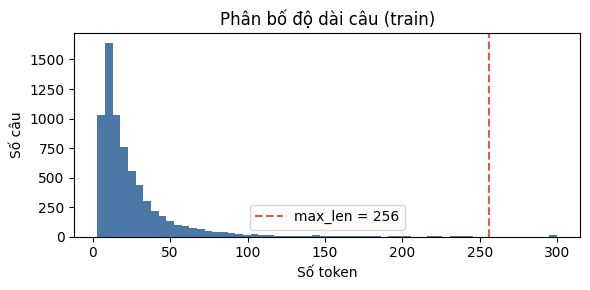

In [10]:
# Thống kê độ dài câu trên train
lens = np.array([len(x) for x in tokenizer(list(train_df[TEXT_COL]))['input_ids']])
print(f'Số token mỗi câu: trung vị {int(np.median(lens))}, 95% câu ≤ {int(np.percentile(lens, 95))}, '
      f'dài nhất {lens.max()}')
print(f'Tỉ lệ câu bị cắt bớt ở max_len = {MAX_LEN}: {(lens > MAX_LEN).mean() * 100:.1f}%')
print('Ví dụ tách token:', tokenizer.tokenize(train_df[TEXT_COL].iloc[0])[:20])

plt.figure(figsize=(6, 3))
plt.hist(np.clip(lens, 0, 300), bins=60, color='#4C78A8')
plt.axvline(MAX_LEN, color='#E45756', ls='--', label=f'max_len = {MAX_LEN}')
plt.xlabel('Số token'); plt.ylabel('Số câu'); plt.title('Phân bố độ dài câu (train)'); plt.legend()
plt.tight_layout(); plt.show()

## 6. Dataset và DataLoader
Dùng *padding động*: mỗi batch chỉ được pad tới độ dài câu dài nhất trong batch đó. Vì đa số câu ngắn, cách này giúp train nhanh hơn nhiều so với pad mọi câu về `max_len`, nhất là khi chạy trên CPU.

In [11]:
from torch.utils.data import Dataset, DataLoader

class TextDataset(Dataset):
    def __init__(self, df):
        self.ids = tokenizer(list(df[TEXT_COL]), truncation=True, max_length=MAX_LEN)['input_ids']
        self.labels = df['label'].tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.ids[i], self.labels[i]

def collate(batch):
    L = max(len(x) for x, _ in batch)
    ids = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return ids, att, torch.tensor([y for _, y in batch])

ds_train, ds_val, ds_test = TextDataset(train_df), TextDataset(val_df), TextDataset(test_df)
dl_val  = DataLoader(ds_val,  batch_size=BATCH_SIZE * 2, collate_fn=collate)
dl_test = DataLoader(ds_test, batch_size=BATCH_SIZE * 2, collate_fn=collate)
print(len(ds_train), len(ds_val), len(ds_test))

7011 997 1992


# Phần B. Huấn luyện
Định nghĩa hàm huấn luyện (mục 7), rồi chạy cho từng seed (mục 8).

## 7. Hàm huấn luyện

- `train_one_epoch(...)`: chạy **1 epoch** huấn luyện, trả về loss trung bình.
- `train_one_seed(seed)`: khởi tạo mô hình, gọi `train_one_epoch` qua từng epoch, theo dõi PR-AUC val để giữ epoch tốt nhất và dừng sớm.

Hai hàm **chỉ huấn luyện**. Mục này không chọn ngưỡng và không tính chỉ số trên test; việc đó nằm ở mục 9–10.

- **Mất cân bằng lớp:** lớp toxic chỉ chiếm khoảng 4% tập train, nên dùng *weighted cross-entropy*. Trọng số lớp toxic bằng tỉ lệ số câu không toxic trên số câu toxic, giới hạn tối đa `MAX_POS_WEIGHT`.
- **Chọn epoch tốt nhất:** theo **PR-AUC trên val**, kèm dừng sớm (`PATIENCE`). Không chọn theo F1, vì val chỉ có khoảng 45 câu toxic nên F1 dao động mạnh giữa các epoch.
- **Tối ưu:** AdamW, warmup tuyến tính, gradient clipping 1.0, fp16 trên GPU.

In [12]:
from sklearn.metrics import average_precision_score

# Trọng số lớp cho weighted cross-entropy
N_CLEAN, N_TOXIC = int((train_df.label == 0).sum()), int((train_df.label == 1).sum())
CLASS_RATIO = N_CLEAN / N_TOXIC
POS_WEIGHT  = min(CLASS_RATIO, MAX_POS_WEIGHT)
print(f'Train: {N_CLEAN} clean / {N_TOXIC} toxic (tỉ lệ {CLASS_RATIO:.1f}) → trọng số lớp toxic = {POS_WEIGHT:.1f}')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict_proba(model, loader):
    """Xác suất lớp toxic cho mọi câu trong loader."""
    model.eval(); out = []
    for ids, att, _ in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def train_one_epoch(model, loader, loss_fn, opt, sched, scaler):
    """Chạy 1 epoch huấn luyện, trả về loss trung bình."""
    model.train(); tot, n = 0.0, 0
    for ids, att, y in loader:
        ids, att, y = ids.to(DEVICE), att.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=ids, attention_mask=att).logits
        loss = loss_fn(logits.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(y); n += len(y)
    return tot / n

def train_one_seed(seed):
    """Fine-tune PhoBERT với một seed; trả về mô hình ở epoch có PR-AUC val cao nhất."""
    set_seed(seed)
    dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
    model = load_with_fallback(AutoModelForSequenceClassification.from_pretrained, MODEL_NAME, num_labels=2).to(DEVICE)
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()

    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, POS_WEIGHT], device=DEVICE))
    opt     = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total   = len(dl_train) * EPOCHS
    sched   = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler  = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    best_ap, best_state, best_ep, history, bad, t0 = -1, None, 0, [], 0, time.time()
    for ep in range(1, EPOCHS + 1):
        loss = train_one_epoch(model, dl_train, loss_fn, opt, sched, scaler)
        ap = average_precision_score(val_df.label, predict_proba(model, dl_val))
        history.append({'epoch': ep, 'train_loss': loss, 'val_pr_auc': ap})
        print(f'  epoch {ep}: loss {loss:.4f} | val PR-AUC {ap:.3f} | {(time.time() - t0) / 60:.1f} phút')

        # Giữ trạng thái tốt nhất theo PR-AUC val, dừng sớm nếu không cải thiện
        if ap > best_ap:
            best_ap, best_ep, bad = ap, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print('  dừng sớm (early stopping)'); break

    model.load_state_dict(best_state)
    return {'model': model, 'history': pd.DataFrame(history), 'val_pr_auc': best_ap,
            'best_epoch': best_ep, 'epochs_ran': len(history),
            'train_minutes': (time.time() - t0) / 60,
            'peak_vram_train_gb': torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == 'cuda' else None}

Train: 6710 clean / 301 toxic (tỉ lệ 22.3) → trọng số lớp toxic = 10.0


## 8. Huấn luyện

Với mỗi seed: huấn luyện → lấy xác suất toxic của mô hình tốt nhất trên val và test → giải phóng bộ nhớ. Chỉ giữ lại mô hình của seed có **PR-AUC val cao nhất** (seed nộp). Mục này chưa tính chỉ số nào.

Trên GPU mỗi seed mất vài phút; thời gian đã chạy được in sau mỗi epoch.

In [13]:
train_runs, histories, val_probs, test_probs = {}, {}, {}, {}
best_model, best_seed, best_val_ap = None, None, -1

for seed in SEEDS:
    print(f'\n===== seed {seed} =====')
    r = train_one_seed(seed)
    histories[seed]  = r['history']
    val_probs[seed]  = predict_proba(r['model'], dl_val)
    test_probs[seed] = predict_proba(r['model'], dl_test)
    train_runs[seed] = {k: r[k] for k in ('best_epoch', 'epochs_ran', 'train_minutes', 'peak_vram_train_gb')}
    print(f"  xong: epoch tốt nhất {r['best_epoch']} | val PR-AUC {r['val_pr_auc']:.3f} | {r['train_minutes']:.1f} phút")
    if r['val_pr_auc'] > best_val_ap:
        best_model, best_seed, best_val_ap = r['model'], seed, r['val_pr_auc']
    del r
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

print(f'\nSeed nộp: {best_seed} (PR-AUC val cao nhất = {best_val_ap:.3f})')


===== seed 42 =====


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

... (4 outputs left out)

  ~0.13 giây/batch → ước tính 0.9 phút/epoch, 4.6 phút cho 5 epoch
  epoch 1: loss 0.4167 | val PR-AUC 0.593 | 0.9 phút
  epoch 2: loss 0.2209 | val PR-AUC 0.721 | 1.9 phút
  epoch 3: loss 0.1005 | val PR-AUC 0.721 | 2.9 phút
  epoch 4: loss 0.0441 | val PR-AUC 0.717 | 3.8 phút
  dừng sớm (early stopping)
  xong: epoch tốt nhất 2 | val PR-AUC 0.721 | 3.8 phút

===== seed 7 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ~0.13 giây/batch → ước tính 1.0 phút/epoch, 4.8 phút cho 5 epoch
  epoch 1: loss 0.4374 | val PR-AUC 0.374 | 0.9 phút
  epoch 2: loss 0.2532 | val PR-AUC 0.673 | 1.9 phút
  epoch 3: loss 0.1374 | val PR-AUC 0.710 | 2.9 phút
  epoch 4: loss 0.0711 | val PR-AUC 0.775 | 3.8 phút
  epoch 5: loss 0.0161 | val PR-AUC 0.760 | 4.8 phút
  xong: epoch tốt nhất 4 | val PR-AUC 0.775 | 4.8 phút

Seed nộp: 7 (PR-AUC val cao nhất = 0.775)


# Phần C. Đánh giá
Định nghĩa hàm đánh giá (mục 9), đánh giá trên val/test (mục 10) và phân tích lỗi (mục 11).

## 9. Hàm đánh giá

- `best_threshold(y, p)`: chọn ngưỡng trên **val** sao cho F1 lớp toxic cao nhất. Ngưỡng này được giữ nguyên khi áp dụng cho test.
- `evaluate(y, p, th)`: tính Accuracy, Precision/Recall/F1 lớp toxic, Macro-F1, PR-AUC, ROC-AUC, Cohen's Kappa và confusion matrix.
- `summary_table(split)`: bảng chỉ số từng seed, kèm trung bình và độ lệch chuẩn.

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve, cohen_kappa_score)

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

def evaluate(y, p, th):
    yhat = (p >= th).astype(int)
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(y, yhat, labels=[0, 1]).ravel())
    return {'threshold': float(th),
            'accuracy': float(accuracy_score(y, yhat)),
            'precision_toxic': float(precision_score(y, yhat, zero_division=0)),
            'recall_toxic': float(recall_score(y, yhat, zero_division=0)),
            'f1_toxic': float(f1_score(y, yhat, zero_division=0)),
            'f1_macro': float(f1_score(y, yhat, average='macro', zero_division=0)),
            'pr_auc': float(average_precision_score(y, p)),
            'roc_auc': float(roc_auc_score(y, p)),
            'cohen_kappa': float(cohen_kappa_score(y, yhat)),
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
            'confusion_matrix': [[tn, fp], [fn, tp]]}

keys  = ['accuracy', 'precision_toxic', 'recall_toxic', 'f1_toxic', 'f1_macro', 'pr_auc', 'roc_auc', 'cohen_kappa',
         'tp', 'fp', 'fn', 'tn']
names = ['Accuracy', 'Precision (toxic)', 'Recall (toxic)', 'F1 (toxic)', 'Macro-F1', 'PR-AUC', 'ROC-AUC', "Cohen's Kappa",
         'TP', 'FP', 'FN', 'TN']

def summary_table(split):
    per = pd.DataFrame([{n: r[split][k] for k, n in zip(keys, names)} for r in results],
                       index=[f'seed {r["seed"]}' + (' (nộp)' if r['seed'] == best_seed else '') for r in results])
    tab = per.copy()
    if len(results) > 1:
        tab.loc['Trung bình'] = per.mean()
        tab.loc['Độ lệch chuẩn'] = per.std(ddof=0)
    return per, tab

summ_of = lambda per: {k: {'mean': float(per[n].mean()), 'std': float(per[n].std(ddof=0))} for k, n in zip(keys, names)}

## 10. Đánh giá trên val và test
Với mỗi seed: chọn ngưỡng trên val, rồi tính chỉ số trên val, trên test (ngưỡng đã chọn) và trên test (ngưỡng cố định 0.5, để so sánh).

In [15]:
y_val, y_test = val_df.label.values, test_df.label.values
thresholds, results = {}, []

for seed in SEEDS:
    th, _ = best_threshold(y_val, val_probs[seed])
    thresholds[seed] = th
    results.append({'seed': seed, **train_runs[seed],
                    'val':  evaluate(y_val, val_probs[seed], th),
                    'test': evaluate(y_test, test_probs[seed], th),
                    'test_threshold_0.5': evaluate(y_test, test_probs[seed], 0.5)})
    rt = results[-1]['test']
    print(f"seed {seed} | ngưỡng {th:.3f} | TEST: P {rt['precision_toxic']:.3f} | R {rt['recall_toxic']:.3f} | "
          f"F1 {rt['f1_toxic']:.3f} | PR-AUC {rt['pr_auc']:.3f} | TP {rt['tp']} FP {rt['fp']} FN {rt['fn']}")

seed 42 | ngưỡng 0.951 | TEST: P 0.641 | R 0.694 | F1 0.667 | PR-AUC 0.642 | TP 59 FP 33 FN 26
seed 13 | ngưỡng 0.992 | TEST: P 0.646 | R 0.600 | F1 0.622 | PR-AUC 0.642 | TP 51 FP 28 FN 34
seed 7 | ngưỡng 0.022 | TEST: P 0.676 | R 0.588 | F1 0.629 | PR-AUC 0.648 | TP 50 FP 24 FN 35


### Bảng kết quả và lưu file

In [16]:
show = lambda t: display(t) if 'display' in globals() else print(t)
per_seed, table = summary_table('test')
print(f'TEST, ngưỡng chọn trên val (seed nộp = {best_seed}, chọn theo PR-AUC val cao nhất):'); show(table.round(4))
per_seed_05, table_05 = summary_table('test_threshold_0.5')
print('TEST, ngưỡng cố định 0.5 (để so sánh):'); show(table_05.round(4))
per_seed_val, table_val = summary_table('val')
print('VAL (ngưỡng tối ưu trên chính val):'); show(table_val.round(4))

seed_cfg = pd.DataFrame([{'Ngưỡng (chọn trên val)': thresholds[r['seed']], 'Epoch tốt nhất': r['best_epoch'],
                          'Số epoch đã chạy': r['epochs_ran'], 'Thời gian train (phút)': r['train_minutes'],
                          'VRAM đỉnh khi train (GB)': r['peak_vram_train_gb']} for r in results],
                        index=[f'seed {r["seed"]}' for r in results])
print('Cấu hình/chi phí từng seed:'); show(seed_cfg.round(3))

summ_of = lambda per: {k: {'mean': float(per[n].mean()), 'std': float(per[n].std(ddof=0))} for k, n in zip(keys, names)}
json.dump({'config': {k: globals()[k] for k in ['MODEL_NAME', 'INPUT_MODE', 'NORMALIZE_TEENCODE', 'SEEDS', 'EPOCHS', 'BATCH_SIZE', 'LR',
                                                'WARMUP', 'MAX_LEN', 'MAX_POS_WEIGHT', 'PATIENCE']},
           'env': ENV, 'best_seed': int(best_seed), 'per_seed': results,
           'test_summary': summ_of(per_seed), 'test_threshold_0.5_summary': summ_of(per_seed_05),
           'val_summary': summ_of(per_seed_val)},
          open(os.path.join(OUT_DIR, 'metrics.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
table.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_test.csv'), encoding='utf-8-sig')
table_05.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_test_nguong_0.5.csv'), encoding='utf-8-sig')
table_val.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_val.csv'), encoding='utf-8-sig')
seed_cfg.round(4).to_csv(os.path.join(OUT_DIR, 'cau_hinh_tung_seed.csv'), encoding='utf-8-sig')
print('Đã lưu metrics.json, ket_qua_test.csv, ket_qua_test_nguong_0.5.csv, ket_qua_val.csv, cau_hinh_tung_seed.csv vào', OUT_DIR)

TEST, ngưỡng chọn trên val (seed nộp = 7, chọn theo PR-AUC val cao nhất):
               Accuracy  Precision (toxic)  Recall (toxic)  F1 (toxic)  \
seed 42          0.9704             0.6413          0.6941      0.6667   
seed 13          0.9689             0.6456          0.6000      0.6220   
seed 7 (nộp)     0.9704             0.6757          0.5882      0.6289   
Trung bình       0.9699             0.6542          0.6275      0.6392   
Độ lệch chuẩn    0.0007             0.0153          0.0474      0.0196   

               Macro-F1  PR-AUC  ROC-AUC  Cohen's Kappa       TP       FP  \
seed 42          0.8256  0.6420   0.9619         0.6512  59.0000  33.0000   
seed 13          0.8029  0.6425   0.9651         0.6057  51.0000  28.0000   
seed 7 (nộp)     0.8068  0.6484   0.9623         0.6136  50.0000  24.0000   
Trung bình       0.8117  0.6443   0.9631         0.6235  53.3333  28.3333   
Độ lệch chuẩn    0.0099  0.0029   0.0015         0.0198   4.0277   3.6818   

                  

### Lưu điểm dự đoán val/test của mọi seed
`val_scores_all_seeds.csv` và `test_scores_all_seeds.csv` (cột `score_seed<seed>` là xác suất lớp toxic). Dùng để:
- kết hợp với SVM (ensemble, định tuyến 2 tầng): trọng số và ngưỡng phải chọn trên **val**, nên cần điểm val;
- kiểm định McNemar giữa PhoBERT và mô hình khác (dùng cột `pred` của `predictions_test.csv` ở mục 11).

In [17]:
val_scores = pd.DataFrame({'review_id': val_df.review_id, 'label': val_df.label,
                           **{f'score_seed{s}': val_probs[s] for s in SEEDS}})
test_scores = pd.DataFrame({'review_id': test_df.review_id, 'label': test_df.label,
                            **{f'score_seed{s}': test_probs[s] for s in SEEDS}})
val_scores.to_csv(os.path.join(OUT_DIR, 'val_scores_all_seeds.csv'), index=False, encoding='utf-8')
test_scores.to_csv(os.path.join(OUT_DIR, 'test_scores_all_seeds.csv'), index=False, encoding='utf-8')
json.dump({'best_seed': int(best_seed), 'thresholds': {int(s): thresholds[s] for s in SEEDS}},
          open(os.path.join(OUT_DIR, 'thresholds.json'), 'w', encoding='utf-8'), indent=2)
print('Đã lưu val_scores_all_seeds.csv, test_scores_all_seeds.csv, thresholds.json vào', OUT_DIR)

Đã lưu val_scores_all_seeds.csv, test_scores_all_seeds.csv, thresholds.json vào /kaggle/working/results/phobert_v2


### Confusion matrix và đường Precision-Recall (seed tốt nhất)

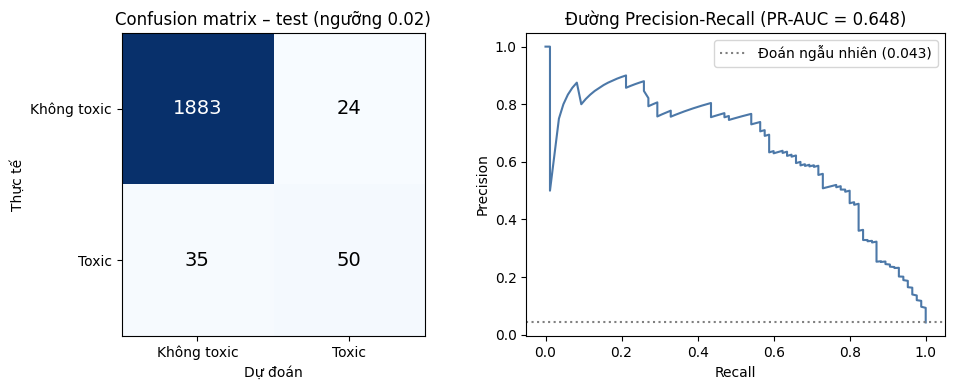

In [18]:
s = best_seed
pt, th = test_probs[s], thresholds[s]
cm = confusion_matrix(test_df.label, (pt >= th).astype(int), labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Không toxic', 'Toxic']); ax.set_yticks([0, 1], ['Không toxic', 'Toxic'])
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title(f'Confusion matrix – test (ngưỡng {th:.2f})')

prec, rec, _ = precision_recall_curve(test_df.label, pt)
axes[1].plot(rec, prec, color='#4C78A8')
axes[1].axhline(test_df.label.mean(), color='gray', ls=':', label=f'Đoán ngẫu nhiên ({test_df.label.mean():.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title(f'Đường Precision-Recall (PR-AUC = {average_precision_score(test_df.label, pt):.3f})')
axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'confusion_matrix_pr_curve.png'), dpi=150); plt.show()

### Đường học (learning curve)

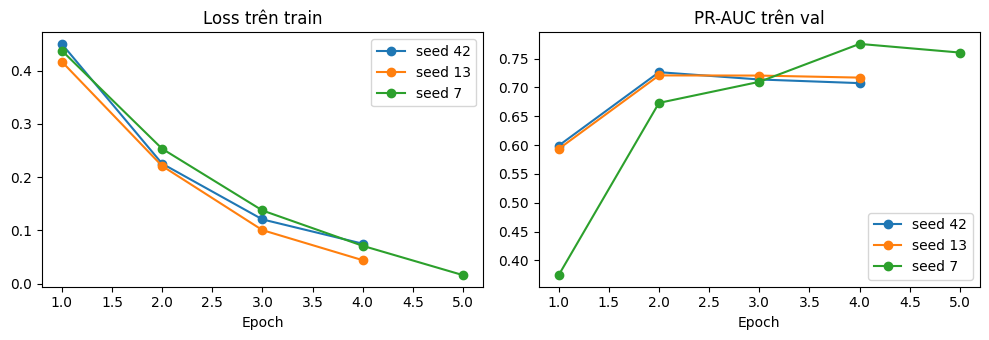

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for s, h in histories.items():
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=f'seed {s}')
    axes[1].plot(h.epoch, h.val_pr_auc, marker='o', label=f'seed {s}')
axes[0].set_title('Loss trên train'); axes[1].set_title('PR-AUC trên val')
for a in axes: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'learning_curve.png'), dpi=150); plt.show()

## 11. Phân tích lỗi
- **Bỏ sót (FN):** câu toxic nhưng mô hình đoán không toxic.
- **Báo nhầm (FP):** câu không toxic nhưng mô hình đoán toxic.

In [20]:
pred = test_df.copy()
pred['prob_toxic'] = test_probs[best_seed]
pred['pred'] = (pred.prob_toxic >= thresholds[best_seed]).astype(int)
pred.to_csv(os.path.join(OUT_DIR, 'predictions_test.csv'), index=False, encoding='utf-8-sig')
err = pred[pred.pred != pred.label].copy()
err['loai_loi'] = np.where(err.label == 1, 'Bỏ sót (FN)', 'Báo nhầm (FP)')
err.sort_values('prob_toxic', ascending=False).to_csv(os.path.join(OUT_DIR, 'errors_test.csv'), index=False, encoding='utf-8-sig')
print(err.loai_loi.value_counts().to_string(), '\n')
pd.set_option('display.max_colwidth', 160)
show = err[['loai_loi', 'prob_toxic', 'noi_dung_goc']].sort_values(['loai_loi', 'prob_toxic'], ascending=[True, False]).head(20)
display(show) if 'display' in globals() else print(show)

loai_loi
Bỏ sót (FN)      35
Báo nhầm (FP)    24 

           loai_loi  prob_toxic  \
1061  Báo nhầm (FP)    0.998931   
1984  Báo nhầm (FP)    0.998914   
1964  Báo nhầm (FP)    0.998866   
559   Báo nhầm (FP)    0.998779   
386   Báo nhầm (FP)    0.998774   
1166  Báo nhầm (FP)    0.998772   
166   Báo nhầm (FP)    0.998713   
1982  Báo nhầm (FP)    0.998711   
1468  Báo nhầm (FP)    0.998598   
713   Báo nhầm (FP)    0.997547   
732   Báo nhầm (FP)    0.997389   
1065  Báo nhầm (FP)    0.996949   
1557  Báo nhầm (FP)    0.996834   
261   Báo nhầm (FP)    0.995930   
1987  Báo nhầm (FP)    0.928539   
679   Báo nhầm (FP)    0.912514   
1699  Báo nhầm (FP)    0.849285   
265   Báo nhầm (FP)    0.120594   
1542  Báo nhầm (FP)    0.100569   
308   Báo nhầm (FP)    0.075041   

                                                                                                                                                         noi_dung_goc  
1061  Quá thất vọng . Nhà ngta đã đi ống nước

### Kiểm tra các review ID mà báo cáo đang trích dẫn
Báo cáo (mục 3.3.2) dùng một số câu làm ví dụ cho phần phân tích lỗi. Ô dưới cho biết PhoBERT của seed nộp dự đoán thế nào với từng câu (đúng/sai, xác suất), để sửa lại phần phân tích cho khớp. Có thể thêm ID khác vào `REPORT_IDS`.

In [21]:
REPORT_IDS = [56417329, 56979900, 59177191, 59425217, 55182406, 51346530, 58055724]
ids = set(map(str, REPORT_IDS))
chk_ids = pred[pred.review_id.astype(str).isin(ids)][['review_id', 'label', 'prob_toxic', 'pred', 'noi_dung_goc']].copy()
chk_ids['ket_qua'] = np.select([(chk_ids.label == 1) & (chk_ids.pred == 1), (chk_ids.label == 0) & (chk_ids.pred == 0),
                                chk_ids.label == 1], ['Đúng (TP)', 'Đúng (TN)', 'Sai: bỏ sót (FN)'], 'Sai: báo nhầm (FP)')
missing = ids - set(chk_ids.review_id.astype(str))
if missing: print('Không thấy trong test.csv:', sorted(missing))
chk_ids.to_csv(os.path.join(OUT_DIR, 'bang_kiem_tra_review_id.csv'), index=False, encoding='utf-8-sig')
display(chk_ids[['review_id', 'label', 'pred', 'prob_toxic', 'ket_qua', 'noi_dung_goc']])

Không thấy trong test.csv: ['55182406']


,review_id,label,pred,prob_toxic,ket_qua,noi_dung_goc
45,59425217,1,1,0.997717,Đúng (TP),Giới thiệu có ngăn đông mềm. Mà quá tệ. Đồ để 3 ngày đã bị hư. Báo lên hãng xún thì nói ngăn đó là ngăn rã đông mềm.OMG. Chứ ko phải ngăn đông mềm. Thật sư ...
77,51346530,1,1,0.691862,Đúng (TP),"Quạt ngăn đông kêu khọt khọt to, tiếng ga bơm lên thì kêu e e ũng to nốt nhưng khi gọi nv của HÃNG TOSHIBA tới thì nói TIẾNG NÀY LÀ BÌNH THƯỜNG, tôi kh biết..."
199,56417329,1,1,0.998774,Đúng (TP),Không nên mua máy của 1 nhãn hàng lớn mà thiếu chuyên nghiệp từ nhân viên đến kiểm tra và cách trả lời của hãng với khách hàng. Lừa những người không có am ...
535,56979900,1,1,0.998696,Đúng (TP),Nhân viên lắp đặt nói chuyện tào lao. Tôi mua máy thương hiệu Nhật cho Ba Mẹ tôi nhưng nhân viên đem tới lắp đặt lại nói là hiệu Việt Nam. Nhân viên ĐMX có ...
541,59177191,1,0,0.000947,Sai: bỏ sót (FN),"Tệ vl, 20.000 mah mà sạc iphone 15promax chưa đc 2 lần. Thua luônẢo ma canada"
693,58055724,1,1,0.998916,Đúng (TP),nấu cơm để trong ngày cơm cũng bị thiêu đem lên bảo hành hết 15 ngày hãng nói không bị gì đem trả về khuyên mọi người né cái hiệu này nha
